In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

2024-01-29 15:06:26.114097: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-01-29 15:06:26.199450: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-01-29 15:06:26.199492: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-01-29 15:06:26.201387: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-01-29 15:06:26.212892: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-01-29 15:06:26.213750: I tensorflow/core/platform/cpu_feature_guard.cc:1

## Params

In [3]:
V_width = 1
V_E_buffer_array = np.arange(8).astype(int)
E_width = 1

# group_size_array = np.array([20,40,60,80])
group_size_array = np.array([20,30,40,50])

N_training_repeats = 5
critic_params = {
    "hidden_dim": 32,
    "embed_dim": 8,
    "layers": 2,
    "activation": "tanh",
}
opt_params = {"track_quantities": False, "quiet": True, "iterations": 1}
mi_measurement_params = {"quiet": True, "batch_size": 500, "N_batches": 500}

train_fraction = 0.5
samp_keep = 1

# shuffle time bins in a way that is the same across movie repeats
shuffle_time = False

# Put variable names here for parameters we want saved.
save_vars = {
    "mi_measurement_params",
    "N_training_repeats",
    "critic_params",
    "opt_params",
    "group_size_array",
    "V_width",
    "V_E_buffer_array",
    "E_width",
    "train_fraction",
    "samp_keep",
    "shuffle_time"
}


## Prepare data

In [4]:
# data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
# D = ds.DataNatScenes(data_path, mov_ind=4)
# mov_ind = D.mov_ind
# mov_name = D.movname
# save_vars.add('mov_ind')

data_path = os.path.join(project_folder, 'data', 'bar_stim_data')
D = ds.DataBar(data_path)
mov_name = 'bar'

# data_path = os.path.join(project_folder, 'data', 'autocorrelation only', 'bar.ds')
# D = ds.load_dataset(data_path)
# mov_name = 'bar strawman'

save_vars.add('mov_name')
print(f'current stimulus is {mov_name}')

current stimulus is bar


In [5]:
# Get neuron sorting indices
# trim_length = 0   # do not trim for strawman data
trim_length = 20   # standard trim for real data

D.reset()
D.trim(trim_length)
V_E_covariance = als.autocorrelation(D.X, dt=1)
sort_by_cov_inds = np.argsort(-np.abs(V_E_covariance))
save_vars.add('sort_by_cov_inds')

## Run analysis

In [10]:
experiment_dims = (len(V_E_buffer_array), len(group_size_array), N_training_repeats)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)

critic_function_array = np.zeros(experiment_dims, dtype=object)
train_points = np.zeros(experiment_dims, dtype=object)
test_points = np.zeros(experiment_dims, dtype=object)
save_vars.update(
    {
        "mi_averages_train",
        "mi_averages_test",
        "mi_stdevs_train",
        "mi_stdevs_test",
        "train_points",
        "test_points",
    }
)

for i, V_E_buffer in tqdm(enumerate(V_E_buffer_array)):
    for j, group_size in enumerate(group_size_array):
        for training_repeat in range(N_training_repeats):
            
            trial_inds = (i, j, training_repeat)

            # Domains, training and test subsets
            D.reset()
            D.trim(trim_length)
            D.subset_features(sort_by_cov_inds)  # sort neurons by VE autocorrelation.
            if shuffle_time:
                D.shuffle_time_and_trial()
            neuron_inds = range(group_size)
            D.subset_features(neuron_inds)
            V, E = D.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep)
            (
                current_train_points,
                current_test_points,
            ) = tools.generate_train_test_indices(V.P, train_fraction)
            train_points[trial_inds] = current_train_points
            test_points[trial_inds] = current_test_points

            # initialize critic function
            critic_function = mds.SeparableCritic(**critic_params)
            
            # Train current
            V.subset_points(current_train_points)
            E.subset_points(current_train_points)
            als.train_NCE(X=V.X, Y=E.X, critic_function=critic_function, **opt_params)

            # Measure InfoNCE for train
            mi_train = als.MI_NCE(
                X=V.X, Y=E.X, critic_function=critic_function, **mi_measurement_params
            )
            mi_averages_train[trial_inds] = mi_train["mi"]
            mi_stdevs_train[trial_inds] = mi_train["mi_stdev"]

            # Measure InfoNCE for test
            V.reset()
            E.reset()
            V.subset_points(current_test_points)
            E.subset_points(current_test_points)
            mi_test = als.MI_NCE(
                X=V.X, Y=E.X, critic_function=critic_function, **mi_measurement_params
            )
            mi_averages_test[trial_inds] = mi_test["mi"]
            mi_stdevs_test[trial_inds] = mi_test["mi_stdev"]

            critic_function_array[trial_inds] = critic_function

0it [00:00, ?it/s]2024-01-29 15:06:57.418341: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2024-01-29 15:06:57.419322: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2256] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...
8it [21:44, 163.02s/it]


## Save

In [11]:
# select variables
critic_type = type(critic_function_array[0, 0])
save_vars.update({"critic_type"})
local_dict = locals()
output_data = {k: local_dict[k] for k in save_vars}

In [12]:
# save things
timestamp = strftime("%Y.%m.%d %Hh %Mm %Ss.dat",gmtime())
# full_file_path = os.path.join(save_directory, strftime("%Y.%m.%d %Hh %Mm %Ss",gmtime())+'.dat')
if shuffle_time:
    prepend = "(shuffled) "
else:
    prepend = ""

stim = mov_name
full_file_path = os.path.join(save_directory, stim,  prepend + 'big.dat')
print(f"data will be saved to:\n{full_file_path}")

data will be saved to:
/home/adam/Documents/projects/retina-past-future-ib/analyses/info decay timescale/saved/bar/big.dat


In [13]:
os.makedirs(os.path.dirname(full_file_path), exist_ok=True)
with open(full_file_path, 'wb+') as f:
            pickle.dump(output_data, f)

## Reload and plot

In [14]:
# stim = 'opticflow'
stim = 'bar'
# stim = 'bar strawman'

In [15]:
load_path = project_folder + f'analyses/info decay timescale/saved/{stim}/big.dat'
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)

load_path_shuffled = project_folder + f'analyses/info decay timescale/saved/{stim}/(shuffled) big.dat'
with open(load_path_shuffled, 'rb') as f:
    data_dict_shuffled = pickle.load(f)
data_shuffled = Namespace(**data_dict_shuffled)

In [16]:
data_dict.keys()

dict_keys(['mov_name', 'opt_params', 'V_width', 'mi_stdevs_train', 'test_points', 'samp_keep', 'mi_averages_test', 'shuffle_time', 'V_E_buffer_array', 'mi_measurement_params', 'E_width', 'critic_params', 'sort_by_cov_inds', 'N_training_repeats', 'train_fraction', 'critic_type', 'train_points', 'mi_stdevs_test', 'mi_averages_train', 'group_size_array'])

In [17]:
average_test = np.average(data.mi_averages_test, axis=-1)
average_train = np.average(data.mi_averages_train, axis=-1)
trial_variance_test = tools.cov_entrywise(data.mi_averages_test, sum_axes=-1)
trial_variance_train = tools.cov_entrywise(data.mi_averages_train, sum_axes=-1)
full_stdevs_train = np.sqrt(np.sum(data.mi_stdevs_train**2, axis=-1) + trial_variance_train)
full_stdevs_test = np.sqrt(np.sum(data.mi_stdevs_test**2, axis=-1) + trial_variance_test)

In [18]:
average_test_shuffled = np.average(data_shuffled.mi_averages_test, axis=-1)
average_train_shuffled = np.average(data_shuffled.mi_averages_train, axis=-1)
trial_variance_test_shuffled = tools.cov_entrywise(data_shuffled.mi_averages_test, sum_axes=-1)
trial_variance_train_shuffled = tools.cov_entrywise(data_shuffled.mi_averages_train, sum_axes=-1)
full_stdevs_train_shuffled = np.sqrt(np.sum(data_shuffled.mi_stdevs_train**2, axis=-1) + trial_variance_train)
full_stdevs_test_shuffled = np.sqrt(np.sum(data_shuffled.mi_stdevs_test**2, axis=-1) + trial_variance_test)

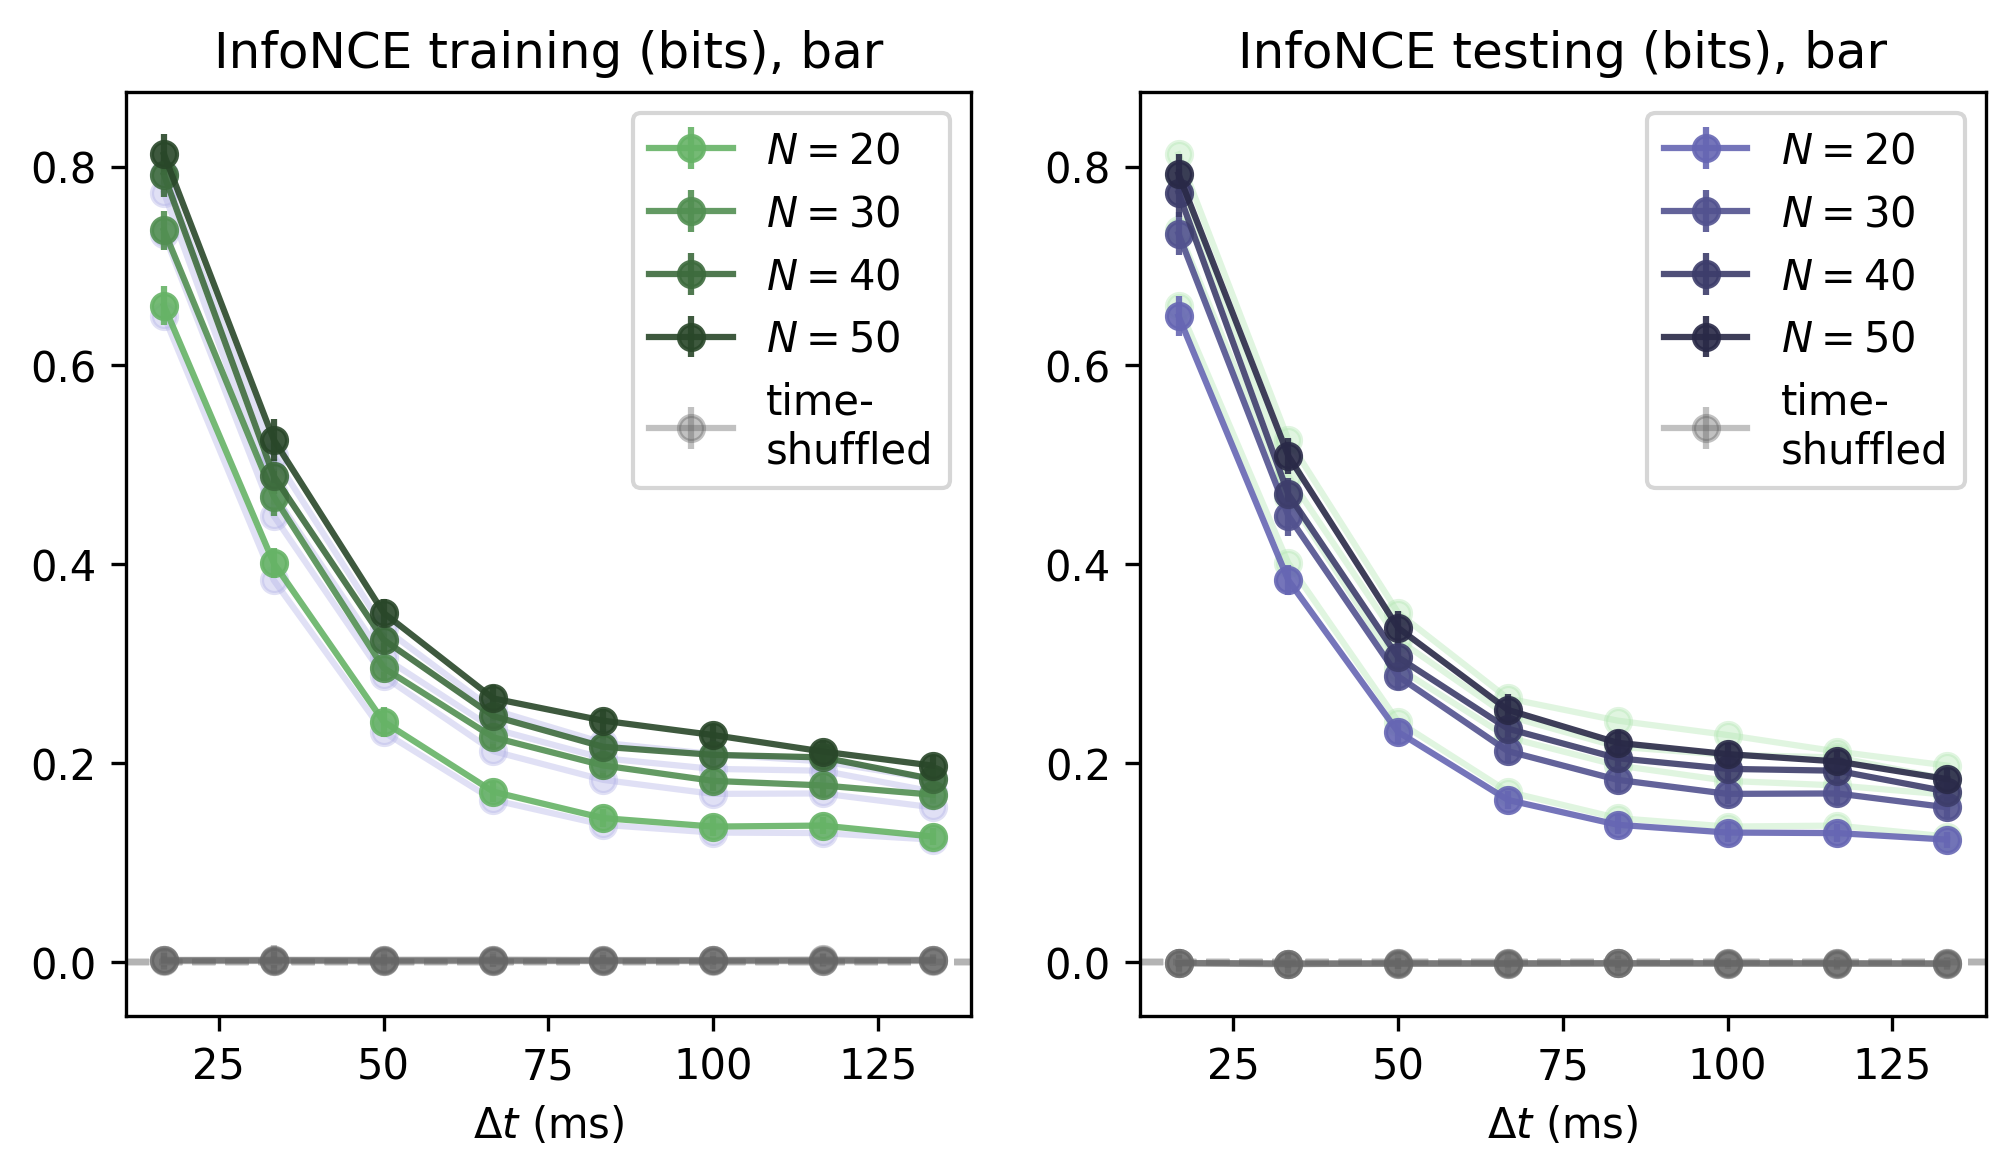

In [19]:
c1 = 0.4
c2 = 0.7
c3 = 0.9
alp1 = 0.4
alp2 = 0.9

binsize = 1000 / 60
x = (data.V_E_buffer_array + 1) * binsize

fig, ax = plt.subplots(ncols=2, figsize=[8,4], dpi=300)
for j, group_size in enumerate(data.group_size_array):
    l = (len(data.group_size_array) - j + 1) / (len(data.group_size_array) + 1)
    
    # Left plot
    ax[0].plot(x, average_test[:,j] / np.log(2), marker='o', color=(c2,c2,c3,alp1));
    ax[0].errorbar(x, average_train[:,j] / np.log(2), yerr=full_stdevs_train[:,j] /np.log(2), marker='o', color=(c1*l,c2*l,c1*l,alp2), label=f'$N=${group_size}');
    # ax[1].set_yticks([])

    # shuffled estimates
    if j == len(data.group_size_array) - 1:
        kwargs = {"label":"time-\nshuffled"}
    else:
        kwargs = {}
    ax[0].errorbar(x, average_train_shuffled[:,j] / np.log(2), yerr=full_stdevs_train_shuffled[:,j] /np.log(2), marker='o', color=(c1,c1,c1,alp1), **kwargs);

    ax[0].axhline(0, color=(c2,c2,c2), linestyle='--')
    ax[0].set_xlabel(r'$\Delta t$ (ms)')
    ax[0].set_title(f'InfoNCE training (bits), {stim}')
    ax[0].legend()
    

    # Right plot
    ax[1].plot(x, average_train[:,j] / np.log(2), marker='o', color=(c2,c3,c2,alp1));
    ax[1].errorbar(x, average_test[:,j] / np.log(2), yerr=full_stdevs_test[:,j] / np.log(2), marker='o', color=(c1*l,c1*l,c2*l,alp2), label=f'$N=${group_size}');
    # ax[1].set_yticks([])

    # shuffled estimates
    if j == len(data.group_size_array) - 1:
        kwargs = {"label":"time-\nshuffled"}
    else:
        kwargs = {}
    ax[1].errorbar(x, average_test_shuffled[:,j] / np.log(2), yerr=full_stdevs_test_shuffled[:,j] /np.log(2), marker='o', color=(c1,c1,c1,alp1), **kwargs);

    ax[1].axhline(0, color=(c2,c2,c2), linestyle='--')
    ax[1].set_xlabel(r'$\Delta t$ (ms)')
    ax[1].set_title(f'InfoNCE testing (bits), {stim}')
    ax[1].legend()

    _, _, ymin, ymax = ax[0].axis()
    ax[1].set_ylim(*(ymin, ymax))

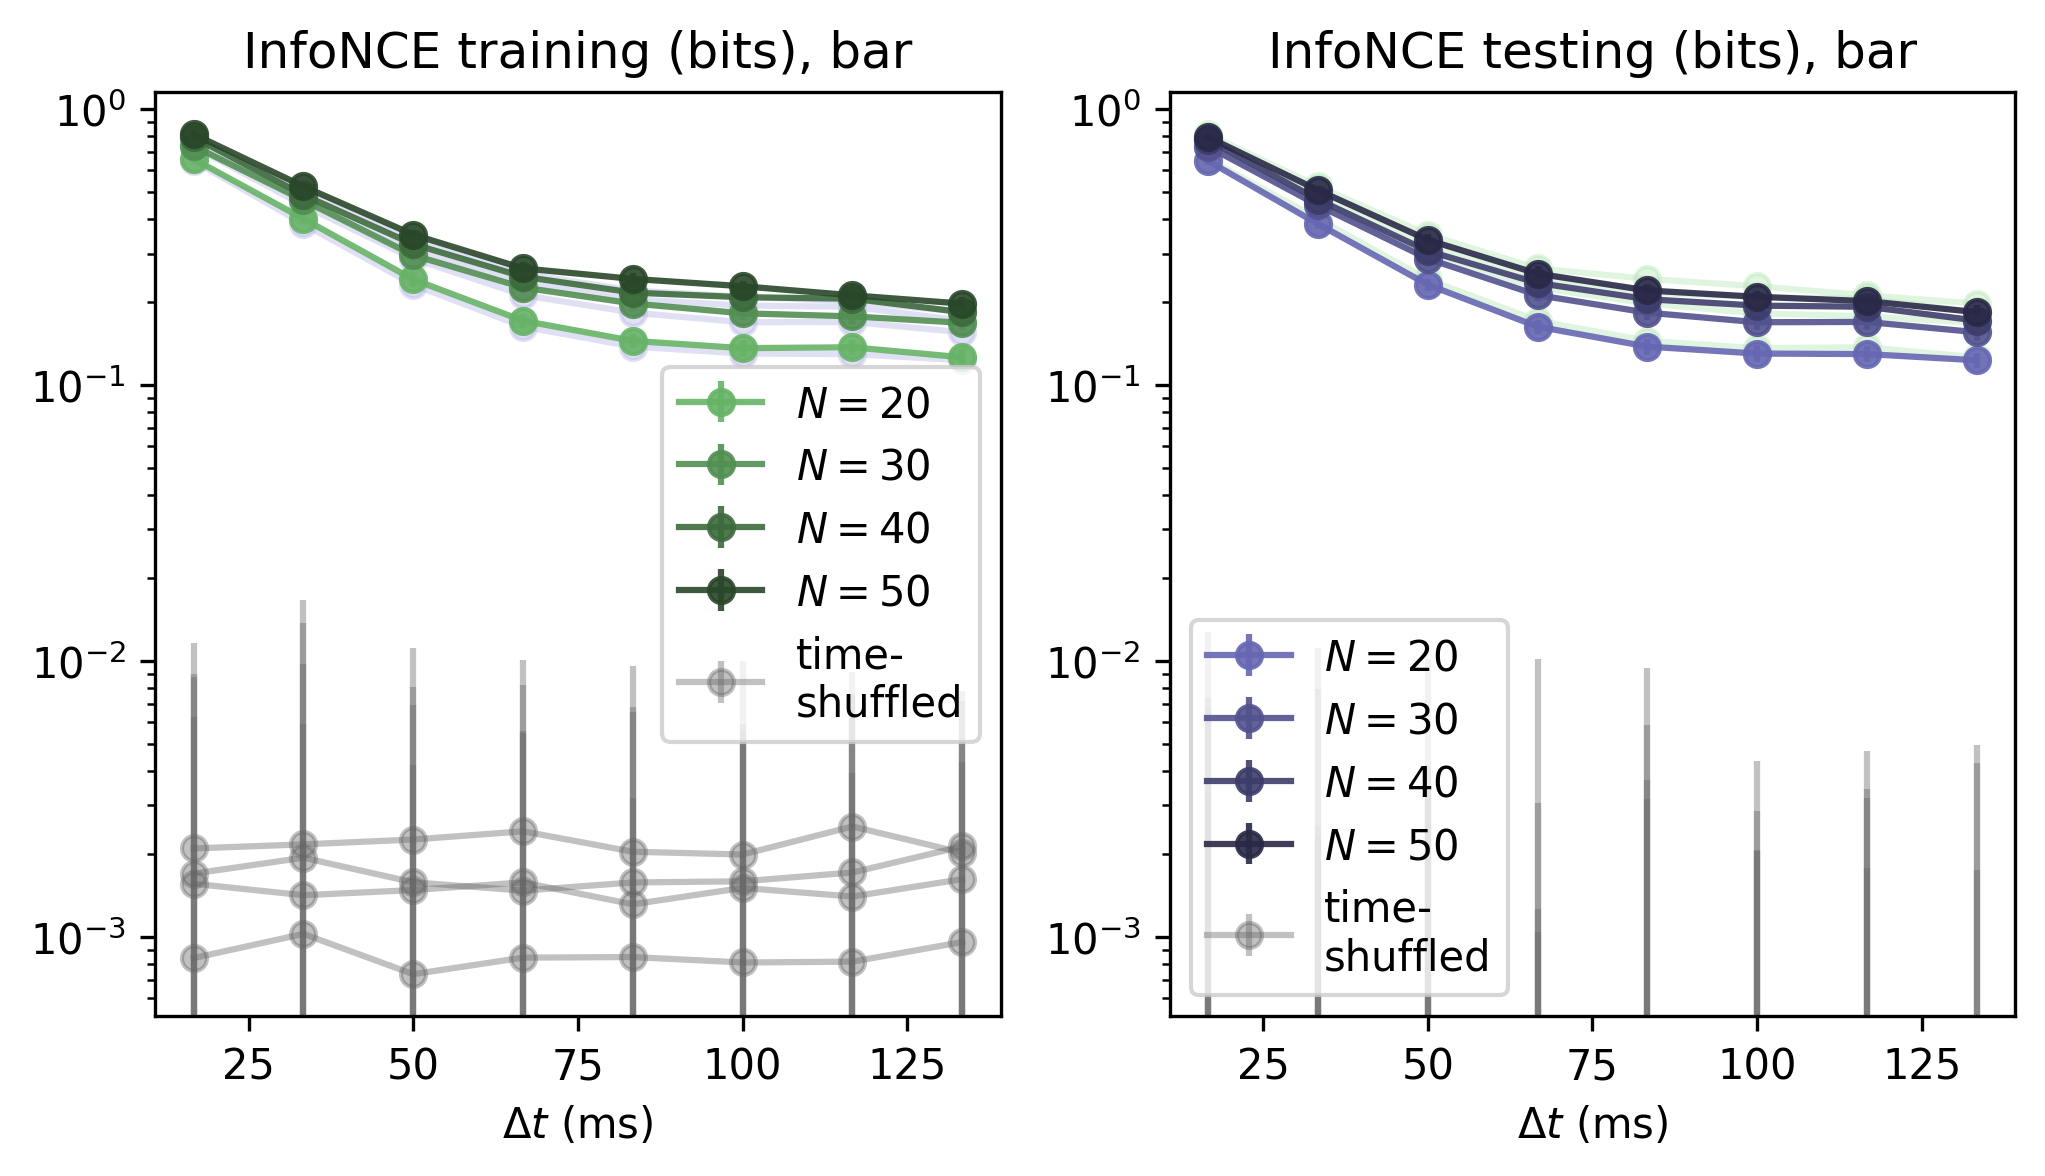

In [20]:
c1 = 0.4
c2 = 0.7
c3 = 0.9
alp1 = 0.4
alp2 = 0.9

binsize = 1000 / 60
x = (data.V_E_buffer_array + 1) * binsize

fig, ax = plt.subplots(ncols=2, figsize=[8,4], dpi=300)
for j, group_size in enumerate(data.group_size_array):
    l = (len(data.group_size_array) - j + 1) / (len(data.group_size_array) + 1)
    
    ax[0].semilogy()
    ax[1].semilogy()
    
    ax[0].plot(x, average_test[:,j] / np.log(2), marker='o', color=(c2,c2,c3,alp1));
    ax[0].errorbar(x, average_train[:,j] / np.log(2), yerr=full_stdevs_train[:,j] / np.log(2), marker='o', color=(c1*l,c2*l,c1*l,alp2), label=f'$N=${group_size}');
    # ax[1].set_yticks([])

    # shuffled estimates
    if j == len(data.group_size_array) - 1:
        kwargs = {"label":"time-\nshuffled"}
    else:
        kwargs = {}
    ax[0].errorbar(x, average_train_shuffled[:,j] / np.log(2), yerr=full_stdevs_train_shuffled[:,j] /np.log(2), marker='o', color=(c1,c1,c1,alp1), **kwargs);

    ax[0].set_xlabel(r'$\Delta t$ (ms)')
    ax[0].set_title(f'InfoNCE training (bits), {stim}')
    ax[0].legend()

    
    ax[1].plot(x, average_train[:,j] / np.log(2), marker='o', color=(c2,c3,c2,alp1));
    ax[1].errorbar(x, average_test[:,j] / np.log(2), yerr=full_stdevs_test[:,j] / np.log(2), marker='o', color=(c1*l,c1*l,c2*l,alp2), label=f'$N=${group_size}');
    # ax[1].set_yticks([])

    # shuffled estimates
    if j == len(data.group_size_array) - 1:
        kwargs = {"label":"time-\nshuffled"}
    else:
        kwargs = {}
    ax[1].errorbar(x, average_test_shuffled[:,j] / np.log(2), yerr=full_stdevs_test_shuffled[:,j] /np.log(2), marker='o', color=(c1,c1,c1,alp1), **kwargs);

    ax[1].set_xlabel(r'$\Delta t$ (ms)')
    ax[1].set_title(f'InfoNCE testing (bits), {stim}')
    ax[1].legend()

    _, _, ymin, ymax = ax[0].axis()
    ax[1].set_ylim(*(ymin, ymax))

In [21]:
y_train = data.mi_averages_train / np.log(2)
y_test = data.mi_averages_test / np.log(2)
tau_train_trialed = np.zeros(y_train.shape[1:])
tau_test_trialed = np.zeros(y_test.shape[1:])
for j, group_size in enumerate(data.group_size_array):
    for repeat in range(data.N_training_repeats):
        tau_train_trialed[j, repeat] = tools.x_half_max(x, y_train[:, j, repeat]) / np.log(2)
        tau_test_trialed[j, repeat] = tools.x_half_max(x, y_test[:, j, repeat]) / np.log(2)
tau_train = np.average(tau_train_trialed, axis=1)
tau_train_err = np.sqrt(tools.cov_entrywise(tau_train_trialed, sum_axes=1))
tau_test = np.average(tau_test_trialed, axis=1)
tau_test_err = np.sqrt(tools.cov_entrywise(tau_test_trialed, sum_axes=1))

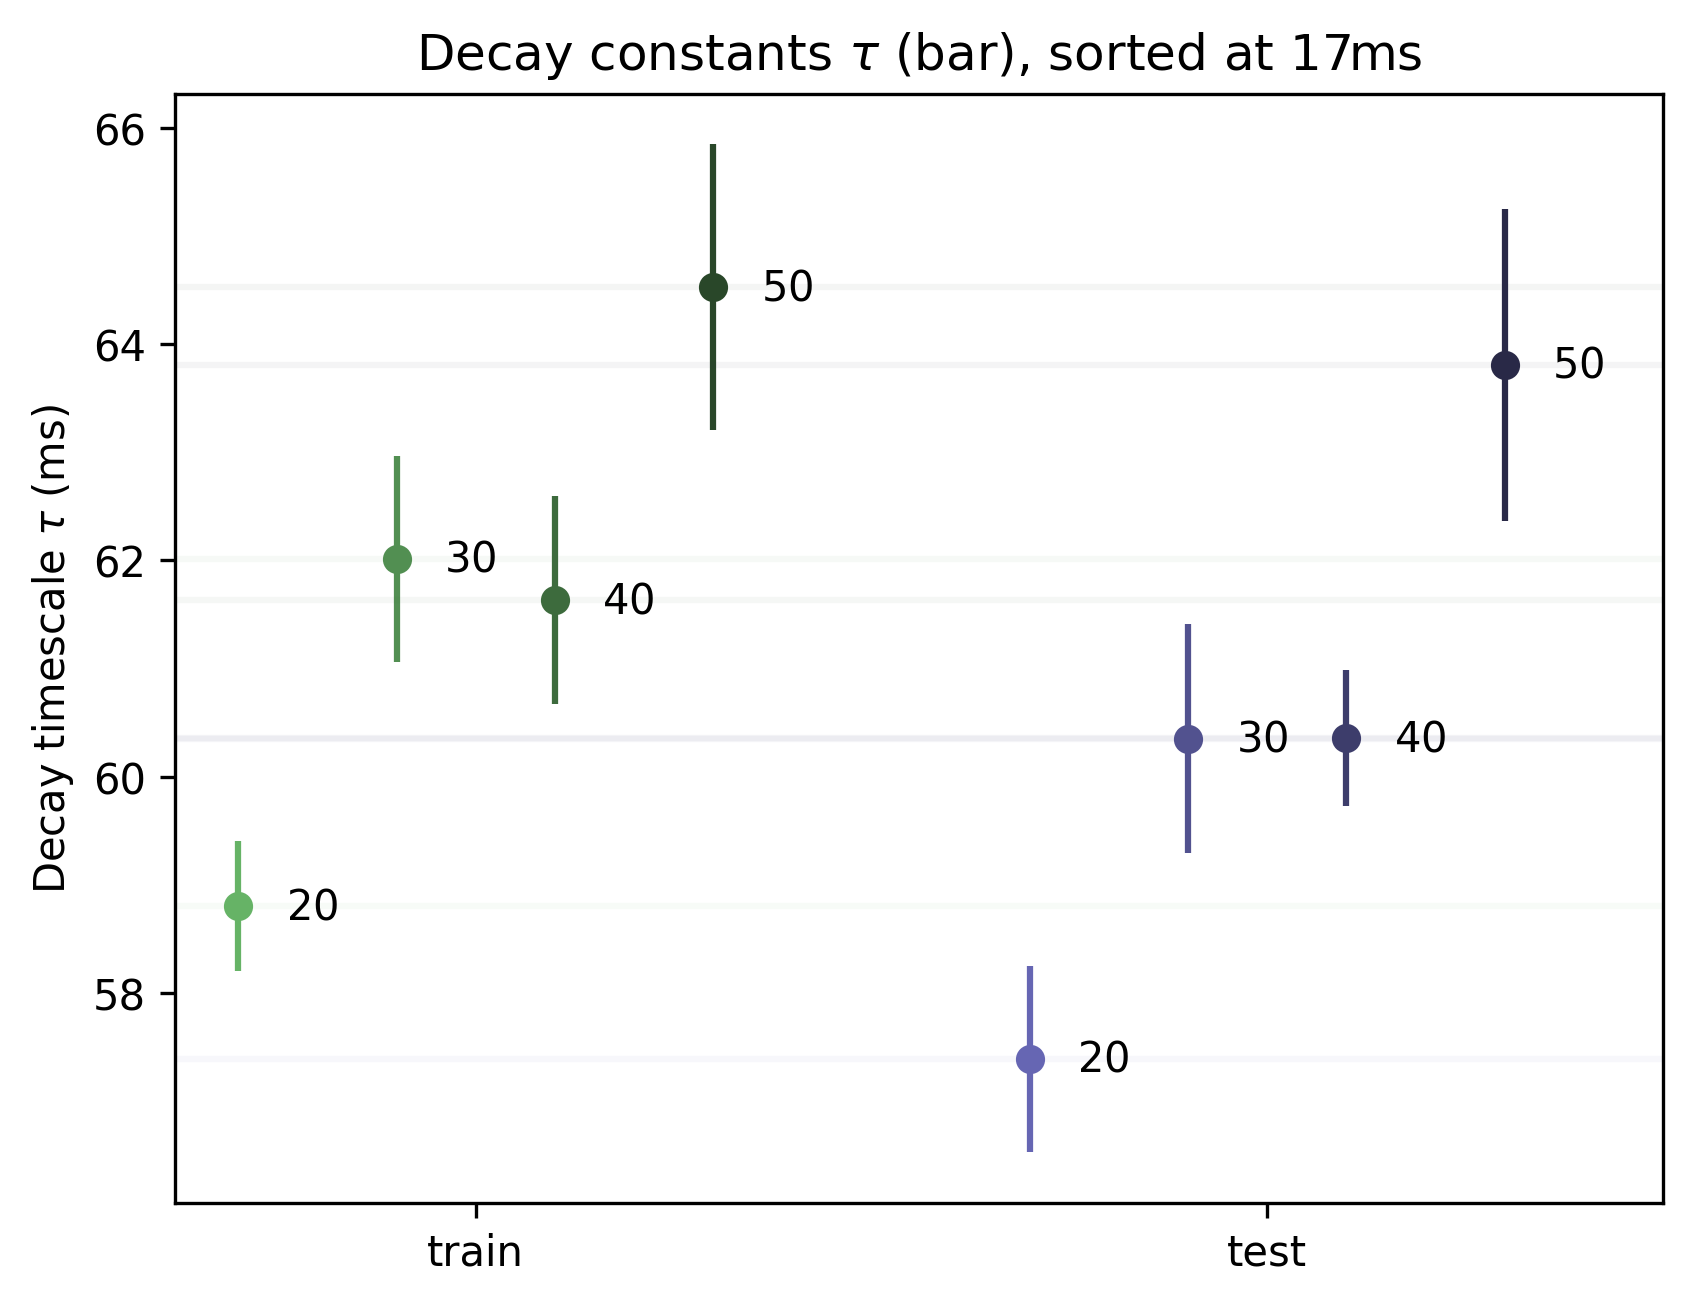

In [22]:
c1 = 0.4
c2 = 0.7
c3 = 0.9
alp0 = 0.05
alp1 = 0.4
alp2 = 0.9

cluster_width = 0.3
spacing = 1
N_group_sizes = len(data.group_size_array)
little_x = np.linspace(-cluster_width, cluster_width, N_group_sizes)

plt.figure(dpi=300)
for i in range(N_group_sizes):
    l = (N_group_sizes - i + 1) / (N_group_sizes + 1)

    plt.axhline(tau_train[i], color=(c1*l,c2*l,c1*l,alp0))
    plt.text(1 * spacing + little_x[i] + cluster_width*0.2, tau_train[i], r'${k}$'.format(k=data.group_size_array[i]), verticalalignment='center');
    plt.errorbar(1 * spacing + little_x[i], tau_train[i], yerr=tau_train_err[i], linestyle='', marker='o', color=(c1*l,c2*l,c1*l))

    plt.axhline(tau_test[i], color=(c1*l,c1*l,c2*l,alp0))
    plt.text(2 * spacing + little_x[i] + cluster_width*0.2, tau_test[i], r'${k}$'.format(k=data.group_size_array[i]), verticalalignment='center');
    plt.errorbar(2 * spacing + little_x[i], tau_test[i], yerr=tau_test_err[i], linestyle='', marker='o', color=(c1*l,c1*l,c2*l))

plt.ylabel(r'Decay timescale $\tau$ (ms)')
# plt.xlabel('group')
plt.title(rf'Decay constants $\tau$ ({stim}), sorted at 17ms')
ax = plt.gca()
ax.set_xticks([spacing, 2*spacing]);
ax.set_xlim(xmax=2.5*spacing)
ax.set_xticklabels(['train', 'test']);